# Forest proximity comparison with RotationForest

This 1.0 tutorial preserves the original comparison's local rotated-XOR dataset and full forest-family roster. Each relation is composed around an ordinary fitted estimator, which remains available as `proximity.estimator`.


All examples use local synthetic data, fixed seeds, and a reduced smoke
configuration by default. `original`, `kerf`, `path`, `random_height`, and the
separately named isolation `collision` relation are symmetric affinities.
`rfgap`, `honest_gap`, and conditional weights are directed query-to-training
weights; downstream visualization, clustering, or attribution must state any
symmetrization. Prediction identity is claimed only for unsymmetrized `rfgap`
or `honest_gap` under their declared bootstrap/honesty contracts.

In [15]:
SMOKE = True
RANDOM_STATE = 0
N_SAMPLES = 80 if SMOKE else 800
N_ESTIMATORS = 20 if SMOKE else 300

In [16]:
import numpy as np
from sklearn.model_selection import train_test_split
from forestgap import load_simulated_dataset

# Preserve the original tutorial's deterministic default dataset.
DATASET_NAME = "rotated_xor"
DATASET_FEATURES = 2

dataset = load_simulated_dataset(
    DATASET_NAME,
    n_samples=N_SAMPLES,
    n_features=DATASET_FEATURES,
    random_state=RANDOM_STATE,
)
X, y = dataset.X, dataset.y
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE,
)
{
    "dataset": dataset.name,
    "description": dataset.description,
    "shape": X.shape,
    "class_counts": np.bincount(y).tolist(),
}

{'dataset': 'rotated_xor',
 'description': 'XOR classification after rotating the 2D feature space.',
 'shape': (80, 2),
 'class_counts': [38, 42]}

In [17]:
import inspect

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import ExtraTreesClassifier, IsolationForest, RandomForestClassifier

from forestgap import Proximity, embed

try:
    from aeon.classification.sklearn import RotationForestClassifier
except ImportError:
    RotationForestClassifier = None

try:
    from treeple import (
        ExtendedIsolationForest,
        ExtraObliqueRandomForestClassifier,
        HonestForestClassifier,
        ObliqueRandomForestClassifier,
        PatchObliqueRandomForestClassifier,
        UnsupervisedObliqueRandomForest,
        UnsupervisedRandomForest,
    )
except ImportError:
    ExtendedIsolationForest = None
    ExtraObliqueRandomForestClassifier = None
    HonestForestClassifier = None
    ObliqueRandomForestClassifier = None
    PatchObliqueRandomForestClassifier = None
    UnsupervisedObliqueRandomForest = None
    UnsupervisedRandomForest = None

## RotationForest RF-GAP identity

`aeon` is optional. When installed, forestgap reconstructs aeon's per-tree
training-estimate roles for OOB/RF-GAP and uses the fitted rotation trees for
external-query weights. The checks below compare unsymmetrized RF-GAP weights
with the parent forest's test and OOB probabilities. OOB rows with no excluded
tree are reported rather than treated as an identity failure.

In [18]:
if RotationForestClassifier is None:
    rotation_forest = None
    rotation_result = {"status": "skipped", "reason": "install forestgap[aeon]"}
else:
    rotation_forest = RotationForestClassifier(
        n_estimators=max(8, N_ESTIMATORS), random_state=RANDOM_STATE, n_jobs=1,
    )
    rotation_rfgap = Proximity(rotation_forest, relation="rfgap").fit(X_train, y_train)
    test_weights = rotation_rfgap.prox_predict(X_test)
    test_error = float(np.max(np.abs(test_weights - rotation_forest.predict_proba(X_test))))

    oob_weights = rotation_rfgap.prox_predict()
    oob_valid = np.asarray(rotation_rfgap.oob_valid_mask_, dtype=bool)
    oob_reference = np.asarray(rotation_forest.oob_decision_function_)
    oob_error = (
        float(np.max(np.abs(oob_weights[oob_valid] - oob_reference[oob_valid])))
        if oob_valid.any()
        else None
    )
    assert test_error < 3e-5
    if oob_error is not None:
        assert oob_error < 3e-5

    rotation_result = {
        "status": "ok",
        "valid_relations": rotation_rfgap.capabilities_.valid_relations,
        "train_shape": rotation_rfgap.get_proximities().shape,
        "test_shape": rotation_rfgap.prox_extend(X_test).shape,
        "test_max_abs_error": test_error,
        "oob_max_abs_error": oob_error,
        "oob_valid_rows": int(oob_valid.sum()),
        "oob_invalid_rows": int((~oob_valid).sum()),
        "rfgap_diagnostics": rotation_rfgap.diagnostics(),
    }
rotation_result

{'status': 'ok',
 'valid_relations': ('kerf',
  'oob',
  'original',
  'path',
  'random_height',
  'rfgap'),
 'train_shape': (60, 60),
 'test_shape': (20, 60),
 'test_max_abs_error': 1.9045546650886536e-07,
 'oob_max_abs_error': 1.61429234424304e-08,
 'oob_valid_rows': 60,
 'oob_invalid_rows': 0,
 'rfgap_diagnostics': {'relation': 'rfgap',
  'shape': (60, 60),
  'directed': True,
  'symmetric': False,
  'psd': None,
  'min_eigenvalue': None,
  'nnz': 1436,
  'density': 0.3988888888888889,
  'value_min': 0.0023809524718672037,
  'value_max': 0.42720797657966614,
  'row_mass_min': 0.9999998807907104,
  'row_mass_max': 1.0000001192092896}}

## RotationForest path relations

Path and random-height relations are symmetric alternatives for geometry and
embedding. They intentionally use separate `Proximity` indexes around the
already fitted RotationForest; no parent forest is refit.

In [19]:
rotation_path_rows = []
if rotation_forest is not None:
    for relation in ("path", "random_height"):
        path_proximity = Proximity(
            rotation_forest, relation=relation, random_state=RANDOM_STATE,
        ).attach(X_train, y_train)
        train_relation = path_proximity.get_proximities()
        diagnostics = path_proximity.diagnostics(train_relation)
        rotation_path_rows.append({
            "relation": relation,
            "train_shape": train_relation.shape,
            "test_shape": path_proximity.prox_extend(X_test).shape,
            "symmetric": diagnostics["symmetric"],
            "psd": diagnostics["psd"],
        })
pd.DataFrame(rotation_path_rows)

,relation,train_shape,test_shape,symmetric,psd
0,path,"(60, 60)","(20, 60)",True,True
1,random_height,"(60, 60)","(20, 60)",True,True


## Full symmetric multi-forest comparison

This restores the original tutorial's eleven-family roster: RandomForest,
ExtraTrees, RotationForest, IsolationForest, three supervised oblique forests,
HonestForest, two unsupervised forests, and Extended Isolation Forest. Optional
families remain visible as skipped rows when their dependency is unavailable.

The embedding uses `path` for supervised forests when the fitted adapter
supports it, original co-leaf affinity as a supervised fallback, original
co-leaf affinity for unsupervised forests, and collision affinity for isolation
forests. RF-GAP is directed and is therefore excluded from Isomap.

In [ ]:
def make_forest(estimator_class):
    parameters = inspect.signature(estimator_class.__init__).parameters
    kwargs = {"n_estimators": N_ESTIMATORS, "random_state": RANDOM_STATE}
    if "n_jobs" in parameters:
        kwargs["n_jobs"] = 1
    if "bootstrap" in parameters:
        kwargs["bootstrap"] = True
    return estimator_class(**kwargs)


family_specs = [
    ("RandomForest", lambda: RandomForestClassifier(
        n_estimators=N_ESTIMATORS, random_state=RANDOM_STATE,
    ), "supervised", None),
    ("ExtraTrees", lambda: ExtraTreesClassifier(
        n_estimators=N_ESTIMATORS, bootstrap=True, random_state=RANDOM_STATE,
    ), "supervised", None),
    ("RotationForest", lambda: rotation_forest, "supervised", "install forestgap[aeon]"),
    ("IsolationForest", lambda: IsolationForest(
        n_estimators=N_ESTIMATORS, random_state=RANDOM_STATE,
    ), "isolation", None),
    ("ObliqueRandomForest", lambda: make_forest(ObliqueRandomForestClassifier)
        if ObliqueRandomForestClassifier is not None else None, "supervised", "install forestgap[treeple]"),
    ("PatchObliqueRandomForest", lambda: make_forest(PatchObliqueRandomForestClassifier)
        if PatchObliqueRandomForestClassifier is not None else None, "supervised", "install forestgap[treeple]"),
    ("ExtraObliqueRandomForest", lambda: make_forest(ExtraObliqueRandomForestClassifier)
        if ExtraObliqueRandomForestClassifier is not None else None, "supervised", "install forestgap[treeple]"),
    # ("HonestForest", lambda: make_forest(HonestForestClassifier)
    #     if HonestForestClassifier is not None else None, "supervised", "install forestgap[treeple]"),
    ("UnsupervisedRandomForest", lambda: make_forest(UnsupervisedRandomForest)
        if UnsupervisedRandomForest is not None else None, "unsupervised", "install forestgap[treeple]"),
    ("UnsupervisedObliqueRandomForest", lambda: make_forest(UnsupervisedObliqueRandomForest)
        if UnsupervisedObliqueRandomForest is not None else None, "unsupervised", "install forestgap[treeple]"),
    ("ExtendedIsolationForest", lambda: make_forest(ExtendedIsolationForest)
        if ExtendedIsolationForest is not None else None, "isolation", "install forestgap[treeple]"),
]


comparison_rows = []
embeddings = {}
for name, factory, family_type, unavailable_reason in family_specs:
    forest = factory()
    if forest is None:
        comparison_rows.append({
            "family": name,
            "status": "skipped",
            "reason": unavailable_reason,
            "relation": None,
            "parent_accuracy": None,
            "density": None,
        })
        continue

    initial_relation = "collision" if family_type == "isolation" else "original"
    indexed = Proximity(forest, relation=initial_relation)
    if family_type == "supervised":
        indexed.fit(X_train, y_train)
    else:
        indexed.fit(X_train)
    relation = (
        "rfgap"
        if family_type == "supervised" and "path" in indexed.capabilities_.valid_relations
        else initial_relation
    )
    proximity = indexed if relation == initial_relation else Proximity(
        forest, relation=relation, random_state=RANDOM_STATE,
    ).attach(X_train, y_train)
    coordinates = embed(proximity, method="isomap", n_components=2, n_neighbors=5)
    embeddings[name] = coordinates
    comparison_rows.append({
        "family": name,
        "status": "ok",
        "reason": None,
        "relation": relation,
        "parent_accuracy": (
            float((forest.predict(X_test) == y_test).mean())
            if family_type == "supervised"
            else None
        ),
        "density": proximity.diagnostics()["density"],
    })

comparison = pd.DataFrame(comparison_rows)
comparison

UnsupportedRelationError: 'isolation_forest' does not support relation 'rfgap': Use score_samples for anomaly scoring; collision is a distinct partition relation.

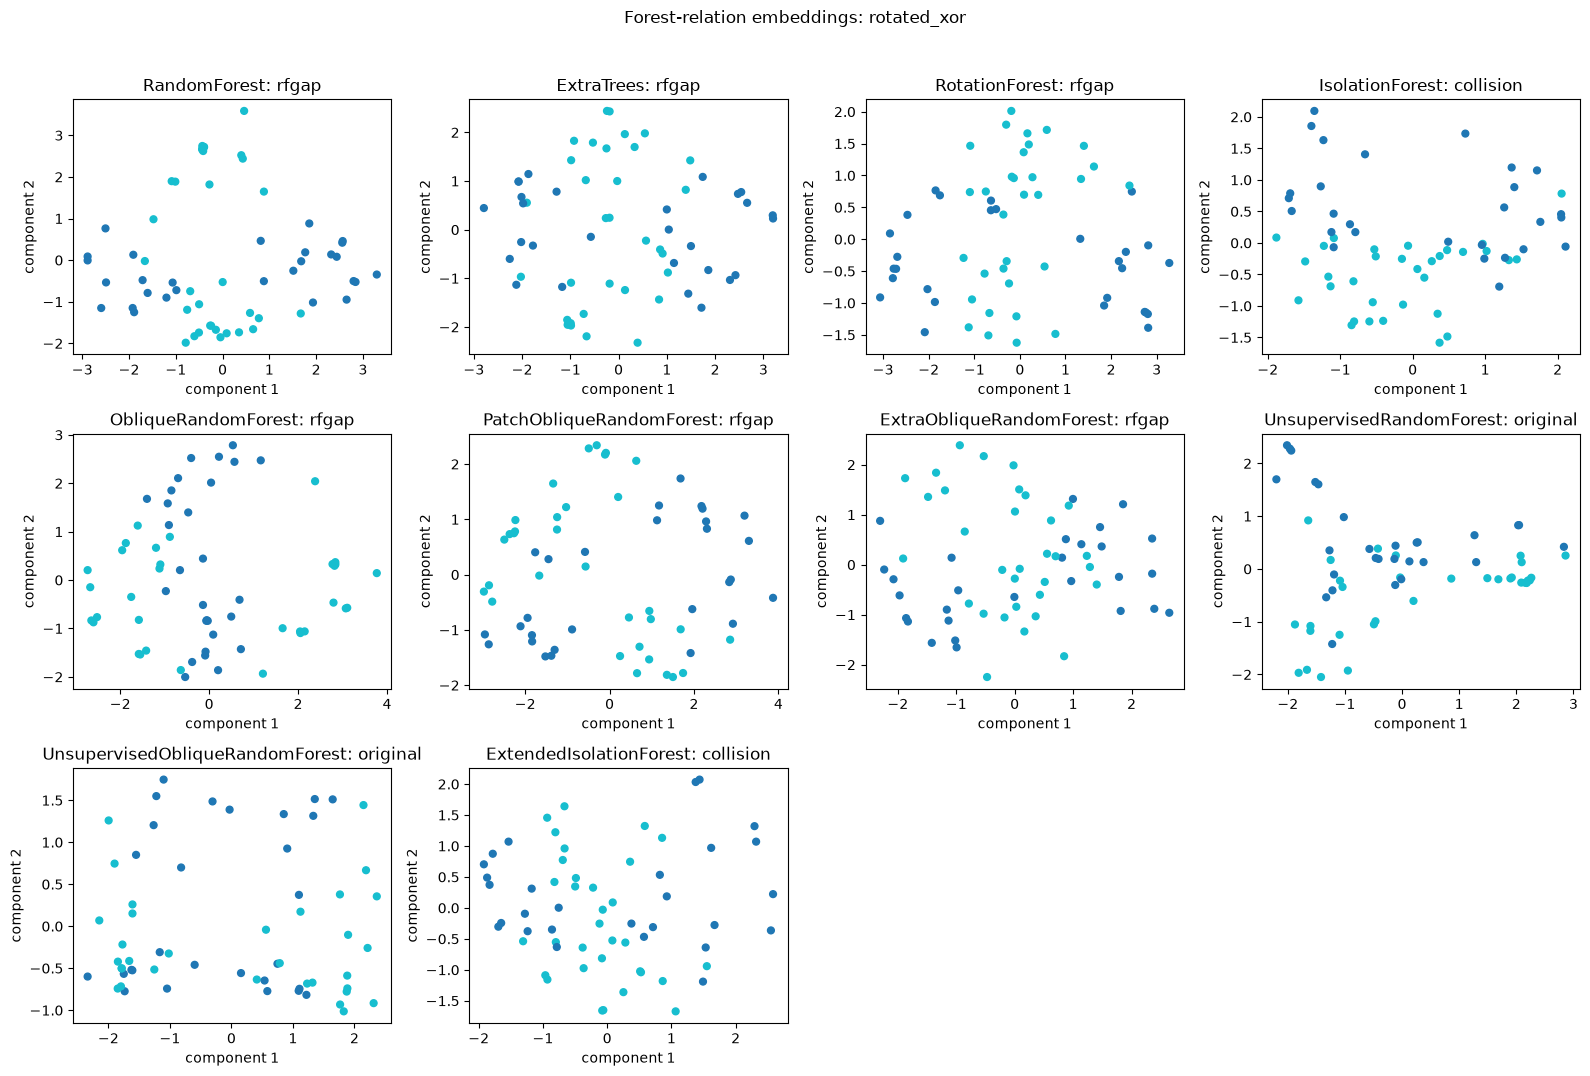

In [ ]:
model_names = list(embeddings)
n_models = len(model_names)
ncols = min(4, n_models)
nrows = int(np.ceil(n_models / ncols))
figure, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.5 * nrows), squeeze=False)
for axis, name in zip(axes.ravel(), model_names):
    coordinates = embeddings[name]
    axis.scatter(coordinates[:, 0], coordinates[:, 1], c=y_train, cmap="tab10", s=24)
    relation = comparison.loc[comparison["family"] == name, "relation"].iat[0]
    axis.set(title=f"{name}: {relation}", xlabel="component 1", ylabel="component 2")
for axis in axes.ravel()[n_models:]:
    axis.axis("off")
figure.suptitle(f"Forest-relation embeddings: {dataset.name}", y=1.02)
figure.tight_layout()

## Reading the comparison

The restored rotated-XOR data makes the contrast between axis-aligned and
rotated/oblique partition geometries visible. Parent accuracy is reported only
as context; compare embeddings only among rows with the same declared
symmetric relation. Use the RF-GAP section above—not these embeddings—when
checking RotationForest prediction identity.